In [1]:
# version 20251124 We consider duration and modified the h definition
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
T = 60                 # horizon
N = 3                   # number of caissons

C_COPER = 15600
C_MANT = 48000
C_LEAK = 100000
K2 = 1.0    #(need to be ajusted)

# big-M
M = 3.5

U = 100                 # max total number (COPER + MANT)
P_threshold = 3.0
P_max = 3.5

b_COPER = 4
b_MANT = 5

# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2

# initial pressures 
P_init = [3.5, 3.5, 3.4]

# alpha values (example, not the real values)
alpha_init = [0.008333, 0.008333, 0.008333]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]


# ----------------------------- Model -----------------------------
mdl = Model(name='model')

# Decision variables
x = mdl.binary_var_matrix(T, N, name='x')          # COPER at t for i
y = mdl.binary_var_matrix(T, N, name='y')          # MANT at t for i
f = mdl.binary_var_matrix(T, N, name='f')          # maintenance in-progress indicator (COPER-window)
g = mdl.binary_var_matrix(T, N, name='g')          # maintenance in-progress indicator (MANT-window)
h_COPER = mdl.binary_var_matrix(T, N, name='h_COPER')  # indicates a COPER action already performed prior to t
h_MANT = mdl.binary_var_matrix(T, N, name='h_MANT')    # indicates a MANT action already performed prior to t
P = mdl.continuous_var_matrix(T, N, lb=-mdl.infinity, ub=mdl.infinity, name='P')     # pressure
v = mdl.continuous_var_matrix(T, N, lb=0.0, name='v')     # net pressure drop due to leakage

# ----------------------------- Objective -----------------------------
mdl.minimize(mdl.sum(C_COPER * x[t, i] + C_MANT * y[t, i] + K2 * C_LEAK * v[t, i] for t in range(T) for i in range(N)))

# ----------------------------- Constraints -----------------------------

# 1) initial pressure
for i in range(N):
    mdl.add_constraint(P[0, i] == P_init[i], ctname=f'initial_P_{i}')

# 2) pressure range for all t,i
for t in range(T):
    for i in range(N):
        # mdl.add_constraint(P[t, i] >= P_threshold, ctname=f'P_lower_{t}_{i}')
        mdl.add_constraint(P[t, i] <= P_max, ctname=f'P_upper_{t}_{i}')

# 3) P restores to P_max after COPER (for t such that t + b_COPER < T)
for t in range(T):
    for i in range(N):
        if t + b_COPER < T:
            mdl.add_constraint(P[t + b_COPER, i] >= P_max - M * (1 - x[t, i]), ctname=f'afterCOPER_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_COPER, i] <= P_max + M * (1 - x[t, i]), ctname=f'afterCOPER_ub_{t}_{i}')

# 4) P restores to P_max after MANT
for t in range(T):
    for i in range(N):
        if t + b_MANT < T:
            mdl.add_constraint(P[t + b_MANT, i] >= P_max - M * (1 - y[t, i]), ctname=f'afterMANT_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_MANT, i] <= P_max + M * (1 - y[t, i]), ctname=f'afterMANT_ub_{t}_{i}')

# 5) h_COPER and h_MANT definitions
for t in range(T):
    for i in range(N):

        # ======================= COPER =======================
        # Case 1 for COPER: t < b_COPER => h must be 0
        if t < b_COPER:
            mdl.add_constraint(h_COPER[t, i] == 0, ctname=f'hCOPER_zero_{t}_{i}')
        else:
            # Case 2 for COPER: h[t] >= x[s] for all s with s + b_COPER <= t
            for s in range(0, t - b_COPER + 1):
                mdl.add_constraint(h_COPER[t, i] >= x[s, i], ctname=f'hCOPER_ge_x_{t}_{i}_from_{s}')

            # Case 3 for COPER: h[t] <= sum x[0 .. t - b_COPER]
            mdl.add_constraint(h_COPER[t, i] <= mdl.sum(x[s, i] for s in range(0, t - b_COPER + 1)), ctname=f'hCOPER_ub_{t}_{i}')

        # ======================= MANT =========================
        # Case 1 for MANT: t < b_MANT => h must be 0
        if t < b_MANT:
            mdl.add_constraint(h_MANT[t, i] == 0, ctname=f'hMANT_zero_{t}_{i}')
        else:
            # Case 2 for MANT: h[t] >= y[s] for all s with s + b_MANT <= t
            for s in range(0, t - b_MANT + 1):
                mdl.add_constraint(h_MANT[t, i] >= y[s, i], ctname=f'hMANT_ge_y_{t}_{i}_from_{s}')

            # Case 3 for MANT: h[t] <= sum y[0 .. t - b_MANT]
            mdl.add_constraint(h_MANT[t, i] <= mdl.sum(y[s, i] for s in range(0, t - b_MANT + 1)), ctname=f'hMANT_ub_{t}_{i}')





# 6) Degradation rate switch (use h_COPER/h_MANT to pick alpha)
for t in range(T-1):
    for i in range(N):
        # 1. f[t,i]=1 : keep same value
        mdl.add_constraint(P[t+1,i] - P[t,i] <= M * (1 - f[t,i]))
        mdl.add_constraint(P[t,i] - P[t+1,i] <= M * (1 - f[t,i]))
        
        # 2. f[t,i]=0, h_COPER[t,i]=1 : decrease by alpha_COPER
        mdl.add_constraint(P[t+1,i] >= (1-alpha_COPER[i]) * P[t,i] - M * (1-h_COPER[t,i] + f[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_COPER[i]) * P[t,i] + M * (1-h_COPER[t,i] + f[t,i]))
        
        # 3. f[t,i]=0, h_COPER[t,i]=0 : decrease by alpha_init
        mdl.add_constraint(P[t+1,i] >= (1-alpha_init[i]) * P[t,i] - M * (h_COPER[t,i] + f[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_init[i]) * P[t,i] + M * (h_COPER[t,i] + f[t,i]))
for t in range(T-1):
    for i in range(N):
        # 1. g[t,i]=1 : keep same value
        mdl.add_constraint(P[t+1,i] - P[t,i] <= M * (1 - g[t,i]))
        mdl.add_constraint(P[t,i] - P[t+1,i] <= M * (1 - g[t,i]))
        
        # 2. g[t,i]=0, h_MANT[t,i]=1 : decrease by alpha_MANT
        mdl.add_constraint(P[t+1,i] >= (1-alpha_MANT[i]) * P[t,i] - M * (1-h_MANT[t,i] + g[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_MANT[i]) * P[t,i] + M * (1-h_MANT[t,i] + g[t,i]))
        
        # 3. g[t,i]=0, h_MANT[t,i]=0 : decrease by alpha_init
        mdl.add_constraint(P[t+1,i] >= (1-alpha_init[i]) * P[t,i] - M * (h_MANT[t,i] + g[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_init[i]) * P[t,i] + M * (h_MANT[t,i] + g[t,i]))


# 7) Pressure stays stable during maintenance


# 8) f, g indicates whether a maintenance is in progress
#    f[t,i] >= x[t-k,i]  for k=0..b_COPER-1  and  f[t,i] <= sum_{k=0..b_COPER-1} x[t-k,i]
for t in range(T):
    for i in range(N):
        # lower bounds: if any start in window, f[t,i] >= that start
        for k in range(0, b_COPER):
            s = t - k
            if s >= 0:
                mdl.add_constraint(f[t, i] >= x[s, i], ctname=f'f_lb_{t}_{i}_from_{s}')
        # upper bound
        idxs = [t - k for k in range(0, b_COPER) if (t - k) >= 0]
        if idxs:
            mdl.add_constraint(f[t, i] <= mdl.sum(x[s, i] for s in idxs), ctname=f'f_ub_{t}_{i}')
        else:
            # no s in window => f <= 0
            mdl.add_constraint(f[t, i] <= 0, ctname=f'f_ub_empty_{t}_{i}')

#    same for g with b_MANT window
for t in range(T):
    for i in range(N):
        for k in range(0, b_MANT):
            s = t - k
            if s >= 0:
                mdl.add_constraint(g[t, i] >= y[s, i], ctname=f'g_lb_{t}_{i}_from_{s}')
        idxs = [t - k for k in range(0, b_MANT) if (t - k) >= 0]
        if idxs:
            mdl.add_constraint(g[t, i] <= mdl.sum(y[s, i] for s in idxs), ctname=f'g_ub_{t}_{i}')
        else:
            mdl.add_constraint(g[t, i] <= 0, ctname=f'g_ub_empty_{t}_{i}')

# 9) net pressure drop: v definition
for t in range(1, T):
    for i in range(N):
        mdl.add_constraint(v[t, i] >= P[t-1, i] - P[t, i], ctname=f'v_def_{t}_{i}')
        mdl.add_constraint(v[t, i] >= 0, ctname=f'v_nonneg_{t}_{i}')

# 10) Total operation number
mdl.add_constraint(mdl.sum(x[t, i] + y[t, i] for t in range(T) for i in range(N)) <= U, ctname='total_ops')

# (Optional) 11) Prevent overlapping starts
# for i in range(N):
#     for t in range(T):
#         for s in range(T):
#             if s < t and (s + b_COPER >= t):
#                 mdl.add_constraint(x[t,i] + x[s,i] <= 1, ctname=f'no_overlap_coper_{t}_{s}_{i}')
#             if s < t and (s + b_MANT >= t):
#                 mdl.add_constraint(y[t,i] + y[s,i] <= 1, ctname=f'no_overlap_mant_{t}_{s}_{i}')

# 11) Single decision at a time for each caisson
for t in range(T):
    for i in range(N):
        mdl.add_constraint(x[t, i] + y[t, i] <= 1, ctname=f'single_decision_{t}_{i}')
# ----------------------------- Solve -----------------------------
# mdl.parameters.timelimit = 300
solution = mdl.solve(log_output=True)

# Print solution summary if found
if solution:
    print("Objective value:", solution.objective_value)
    # print some pressure values for first caisson as example
    for i in range(N):
        ps = [P[t, i].solution_value for t in range(min(T, 30))]
        xs = [x[t, i].solution_value for t in range(min(T, 30))]
        ys = [y[t, i].solution_value for t in range(min(T, 30))]
        fs = [f[t, i].solution_value for t in range(min(T, 30))]
        gs = [g[t, i].solution_value for t in range(min(T, 30))]
        hs_c = [h_COPER[t, i].solution_value for t in range(min(T, 30))]
        hs_m = [h_MANT[t, i].solution_value for t in range(min(T, 30))]
        vs = [v[t, i].solution_value for t in range(min(T, 30))]
        print(f"\nCaisson {i}:")
        print("P[0..29]  :", ps)
        print("x[0..29]  :", xs)
        print("y[0..29]  :", ys)
        print("f[0..29]  :", fs)
        print("g[0..29]  :", gs)
        print("h_COPER.. :", hs_c)
        print("h_MANT... :", hs_m)
        print("v[0..29]  :", vs)
else:
    print("No solution found. Analyzing conflicts...")

    # get CPLEX object
    cpx = mdl.get_cplex()

    # disable solver output
    cpx.set_results_stream(None)
    cpx.set_warning_stream(None)
    cpx.set_log_stream(None)

    # run conflict analysis
    cpx.conflict.refine()

    # write conflict analysis results to file
    conflict_file = "conflict_results.txt"
    cpx.conflict.write(conflict_file)
    print(f"Conflict analysis report written to '{conflict_file}'")



Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Tried aggregator 7 times.
MIP Presolve eliminated 5520 rows and 305 columns.
MIP Presolve modified 7765 coefficients.
Aggregator did 84 substitutions.
Reduced MIP has 9604 rows, 1051 columns, and 28618 nonzeros.
Reduced MIP has 783 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.55 sec. (557.80 ticks)
Found incumbent of value 405225.959709 after 0.56 sec. (561.87 ticks)
Probing fixed 156 vars, tightened 107 bounds.
Probing changed sense of 159 constraints.
Probing time = 0.08 sec. (41.13 ticks)
Tried aggregator 6 times.
MIP Presolve eliminated 7858 rows and 633 columns.
MIP Presolve modified 5035 coefficients.
Aggregator did 66 substitutions.
Reduced MIP has 1680 rows, 352 columns, and 5090 nonzeros.
Reduced MIP has 256 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.31 sec. (238.63 ticks)
Probing fixed 244 vars, tightened 148 bounds.
Probing chan

In [ ]:
# version 20251123 h definition problem
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
T = 20                 # horizon
N = 3                   # number of caissons

C_COPER = 15600
C_MANT = 48000
C_LEAK = 100000
K2 = 1.0    #(need to be ajusted)

# big-M
M = 3.5

U = 100                 # max total number (COPER + MANT)
P_threshold = 3.0
P_max = 3.5

b_COPER = 4
b_MANT = 5

# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2

# initial pressures 
P_init = [3.5, 3.5, 3.4]

# alpha values (example, not the real values)
alpha_init = [0.008333, 0.008333, 0.008333]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]


# ----------------------------- Model -----------------------------
mdl = Model(name='model')

# Decision variables
x = mdl.binary_var_matrix(T, N, name='x')          # COPER at t for i
y = mdl.binary_var_matrix(T, N, name='y')          # MANT at t for i
f = mdl.binary_var_matrix(T, N, name='f')          # maintenance in-progress indicator (COPER-window)
g = mdl.binary_var_matrix(T, N, name='g')          # maintenance in-progress indicator (MANT-window)
h_COPER = mdl.binary_var_matrix(T, N, name='h_COPER')  # indicates a COPER action already performed prior to t
h_MANT = mdl.binary_var_matrix(T, N, name='h_MANT')    # indicates a MANT action already performed prior to t
P = mdl.continuous_var_matrix(T, N, lb=-mdl.infinity, ub=mdl.infinity, name='P')     # pressure
v = mdl.continuous_var_matrix(T, N, lb=0.0, name='v')     # net pressure drop due to leakage

# ----------------------------- Objective -----------------------------
mdl.minimize(mdl.sum(C_COPER * x[t, i] + C_MANT * y[t, i] + K2 * C_LEAK * v[t, i] for t in range(T) for i in range(N)))

# ----------------------------- Constraints -----------------------------

# 1) initial pressure
for i in range(N):
    mdl.add_constraint(P[0, i] == P_init[i], ctname=f'initial_P_{i}')

# 2) pressure range for all t,i
for t in range(T):
    for i in range(N):
        mdl.add_constraint(P[t, i] >= P_threshold, ctname=f'P_lower_{t}_{i}')
        mdl.add_constraint(P[t, i] <= P_max, ctname=f'P_upper_{t}_{i}')

# 3) P restores to P_max after COPER (for t such that t + b_COPER < T)
for t in range(T):
    for i in range(N):
        if t + b_COPER < T:
            mdl.add_constraint(P[t + b_COPER, i] >= P_max - M * (1 - x[t, i]), ctname=f'afterCOPER_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_COPER, i] <= P_max + M * (1 - x[t, i]), ctname=f'afterCOPER_ub_{t}_{i}')

# 4) P restores to P_max after MANT
for t in range(T):
    for i in range(N):
        if t + b_MANT < T:
            mdl.add_constraint(P[t + b_MANT, i] >= P_max - M * (1 - y[t, i]), ctname=f'afterMANT_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_MANT, i] <= P_max + M * (1 - y[t, i]), ctname=f'afterMANT_ub_{t}_{i}')

# 5) h_COPER and h_MANT definitions
# h_{t,i} >= x_{s,i} for all s < t  AND  h_{t,i} <= sum_{s=0}^{t-1} x_{s,i}
# for t in range(T):
#     for i in range(N):
#         # lower bounds: for all s < t, h >= x[s,i]
#         for s in range(0, t):   # empty when t=0
#             mdl.add_constraint(h_COPER[t, i] >= x[s, i], ctname=f'hCOPER_ge_x_{t}_{i}_from_{s}')
#             mdl.add_constraint(h_MANT[t, i] >= y[s, i], ctname=f'hMANT_ge_y_{t}_{i}_from_{s}')
#         # upper bounds: h <= sum_{s=0}^{t-1} x[s,i]
#         if t == 0:
#             # sum over empty set = 0
#             mdl.add_constraint(h_COPER[t, i] <= 0, ctname=f'hCOPER_ub_{t}_{i}_empty')
#             mdl.add_constraint(h_MANT[t, i] <= 0, ctname=f'hMANT_ub_{t}_{i}_empty')
#         else:
#             mdl.add_constraint(h_COPER[t, i] <= mdl.sum(x[s, i] for s in range(0, t)), ctname=f'hCOPER_ub_{t}_{i}')
#             mdl.add_constraint(h_MANT[t, i] <= mdl.sum(y[s, i] for s in range(0, t)), ctname=f'hMANT_ub_{t}_{i}')


for t in range(T):
    for i in range(N):

        # ======================= COPER =======================
        # Case 1 for COPER: t < b_COPER => h must be 0
        if t < b_COPER:
            mdl.add_constraint(h_COPER[t, i] == 0, ctname=f'hCOPER_zero_{t}_{i}')
        else:
            # Case 2 for COPER: h[t] >= x[s] for all s with s + b_COPER <= t
            for s in range(0, t - b_COPER + 1):
                mdl.add_constraint(h_COPER[t, i] >= x[s, i], ctname=f'hCOPER_ge_x_{t}_{i}_from_{s}')

            # Case 3 for COPER: h[t] <= sum x[0 .. t - b_COPER]
            mdl.add_constraint(h_COPER[t, i] <= mdl.sum(x[s, i] for s in range(0, t - b_COPER + 1)), ctname=f'hCOPER_ub_{t}_{i}')

        # ======================= MANT =========================
        # Case 1 for MANT: t < b_MANT => h must be 0
        if t < b_MANT:
            mdl.add_constraint(h_MANT[t, i] == 0, ctname=f'hMANT_zero_{t}_{i}')
        else:
            # Case 2 for MANT: h[t] >= y[s] for all s with s + b_MANT <= t
            for s in range(0, t - b_MANT + 1):
                mdl.add_constraint(h_MANT[t, i] >= y[s, i], ctname=f'hMANT_ge_y_{t}_{i}_from_{s}')

            # Case 3 for MANT: h[t] <= sum y[0 .. t - b_MANT]
            mdl.add_constraint(h_MANT[t, i] <= mdl.sum(y[s, i] for s in range(0, t - b_MANT + 1)), ctname=f'hMANT_ub_{t}_{i}')





# 6) Degradation rate switch (use h_COPER/h_MANT to pick alpha)
for t in range(T - 1):
    for i in range(N):
        # when h_COPER[t,i] = 1 -> P[t+1] approx (1-alpha_COPER) * P[t]
        mdl.add_constraint(P[t + 1, i] >= (1 - alpha_COPER[i]) * P[t, i] - M * (1 - h_COPER[t, i]), ctname=f'PE_hCOPER_lb_{t}_{i}')
        mdl.add_constraint(P[t + 1, i] <= (1 - alpha_COPER[i]) * P[t, i] + M * (1 - h_COPER[t, i]), ctname=f'PE_hCOPER_ub_{t}_{i}')

        # when h_MANT[t,i] = 1 -> P[t+1] approx (1-alpha_MANT) * P[t]
        mdl.add_constraint(P[t + 1, i] >= (1 - alpha_MANT[i]) * P[t, i] - M * (1 - h_MANT[t, i]), ctname=f'PE_hMANT_lb_{t}_{i}')
        mdl.add_constraint(P[t + 1, i] <= (1 - alpha_MANT[i]) * P[t, i] + M * (1 - h_MANT[t, i]), ctname=f'PE_hMANT_ub_{t}_{i}')

        # when h_COPER==0 and h_MANT==0
        mdl.add_constraint(P[t + 1, i] >= (1 - alpha_init[i]) * P[t, i] - M * (h_COPER[t, i] + h_MANT[t, i]), ctname=f'PE_0_lb_{t}_{i}')
        mdl.add_constraint(P[t + 1, i] <= (1 - alpha_init[i]) * P[t, i] + M * (h_COPER[t, i] + h_MANT[t, i]), ctname=f'PE_0_ub_{t}_{i}')

# 7) Pressure stays stable during maintenance
# #    For each start x[t,i]==1, for k=1..b_COPER-1 enforce P[t+k,i] == P[t,i]
# for t in range(T):
#     for i in range(N):
#         for k in range(1, b_COPER):
#             if t + k < T:
#                 mdl.add_constraint(P[t + k, i] >= P[t, i] - M * (1 - x[t, i]), ctname=f'COPER_hold_lb_{t}_{i}_k{k}')
#                 mdl.add_constraint(P[t + k, i] <= P[t, i] + M * (1 - x[t, i]), ctname=f'COPER_hold_ub_{t}_{i}_k{k}')

# #    For MANT windows
# for t in range(T):
#     for i in range(N):
#         for k in range(1, b_MANT):
#             if t + k < T:
#                 mdl.add_constraint(P[t + k, i] >= P[t, i] - M * (1 - y[t, i]), ctname=f'MANT_hold_lb_{t}_{i}_k{k}')
#                 mdl.add_constraint(P[t + k, i] <= P[t, i] + M * (1 - y[t, i]), ctname=f'MANT_hold_ub_{t}_{i}_k{k}')

# 8) f, g indicates whether a maintenance is in progress
# #    f[t,i] >= x[t-k,i]  for k=0..b_COPER-1  and  f[t,i] <= sum_{k=0..b_COPER-1} x[t-k,i]
# for t in range(T):
#     for i in range(N):
#         # lower bounds: if any start in window, f[t,i] >= that start
#         for k in range(0, b_COPER):
#             s = t - k
#             if s >= 0:
#                 mdl.add_constraint(f[t, i] >= x[s, i], ctname=f'f_lb_{t}_{i}_from_{s}')
#         # upper bound
#         idxs = [t - k for k in range(0, b_COPER) if (t - k) >= 0]
#         if idxs:
#             mdl.add_constraint(f[t, i] <= mdl.sum(x[s, i] for s in idxs), ctname=f'f_ub_{t}_{i}')
#         else:
#             # no s in window => f <= 0
#             mdl.add_constraint(f[t, i] <= 0, ctname=f'f_ub_empty_{t}_{i}')

# #    same for g with b_MANT window
# for t in range(T):
#     for i in range(N):
#         for k in range(0, b_MANT):
#             s = t - k
#             if s >= 0:
#                 mdl.add_constraint(g[t, i] >= y[s, i], ctname=f'g_lb_{t}_{i}_from_{s}')
#         idxs = [t - k for k in range(0, b_MANT) if (t - k) >= 0]
#         if idxs:
#             mdl.add_constraint(g[t, i] <= mdl.sum(y[s, i] for s in idxs), ctname=f'g_ub_{t}_{i}')
#         else:
#             mdl.add_constraint(g[t, i] <= 0, ctname=f'g_ub_empty_{t}_{i}')

# 9) net pressure drop: v definition
for t in range(1, T):
    for i in range(N):
        mdl.add_constraint(v[t, i] >= P[t-1, i] - P[t, i], ctname=f'v_def_{t}_{i}')
        mdl.add_constraint(v[t, i] >= 0, ctname=f'v_nonneg_{t}_{i}')

# 10) Total operation number
mdl.add_constraint(mdl.sum(x[t, i] + y[t, i] for t in range(T) for i in range(N)) <= U, ctname='total_ops')

# (Optional) 11) Prevent overlapping starts
# for i in range(N):
#     for t in range(T):
#         for s in range(T):
#             if s < t and (s + b_COPER >= t):
#                 mdl.add_constraint(x[t,i] + x[s,i] <= 1, ctname=f'no_overlap_coper_{t}_{s}_{i}')
#             if s < t and (s + b_MANT >= t):
#                 mdl.add_constraint(y[t,i] + y[s,i] <= 1, ctname=f'no_overlap_mant_{t}_{s}_{i}')

# ----------------------------- Solve -----------------------------
# mdl.parameters.timelimit = 300
solution = mdl.solve(log_output=True)

# Print solution summary if found
if solution:
    print("Objective value:", solution.objective_value)
    # print some pressure values for first caisson as example
    for i in range(N):
        ps = [P[t, i].solution_value for t in range(min(T, 30))]
        xs = [x[t, i].solution_value for t in range(min(T, 30))]
        ys = [y[t, i].solution_value for t in range(min(T, 30))]
        fs = [f[t, i].solution_value for t in range(min(T, 30))]
        gs = [g[t, i].solution_value for t in range(min(T, 30))]
        hs_c = [h_COPER[t, i].solution_value for t in range(min(T, 30))]
        hs_m = [h_MANT[t, i].solution_value for t in range(min(T, 30))]
        vs = [v[t, i].solution_value for t in range(min(T, 30))]
        print(f"\nCaisson {i}:")
        print("P[0..29]  :", ps)
        print("x[0..29]  :", xs)
        print("y[0..29]  :", ys)
        print("f[0..29]  :", fs)
        print("g[0..29]  :", gs)
        print("h_COPER.. :", hs_c)
        print("h_MANT... :", hs_m)
        print("v[0..29]  :", vs)
else:
    print("No solution found. Analyzing conflicts...")

    # get CPLEX object
    cpx = mdl.get_cplex()

    # disable solver output
    cpx.set_results_stream(None)
    cpx.set_warning_stream(None)
    cpx.set_log_stream(None)

    # run conflict analysis
    cpx.conflict.refine()

    # write conflict analysis results to file
    conflict_file = "conflict_results.txt"
    cpx.conflict.write(conflict_file)
    print(f"Conflict analysis report written to '{conflict_file}'")



Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Row 'PE_0_ub_14_2' infeasible, all entries at implied bounds.
Presolve time = 0.00 sec. (0.89 ticks)

Root node processing (before b&c):
  Real time             =    0.01 sec. (1.06 ticks)
Parallel b&c, 8 threads:
  Real time             =    0.00 sec. (0.00 ticks)
  Sync time (average)   =    0.00 sec.
  Wait time (average)   =    0.00 sec.
                          ------------
Total (root+branch&cut) =    0.01 sec. (1.06 ticks)
No solution found. Analyzing conflicts...
Conflict analysis report written to 'conflict_results.txt'


In [1]:
# Event-based model
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
N = 3                 # number of caissons
T = 60.0              # planning horizon (continuous)
C_COPER = 15600
C_MANT = 48000
C_LEAK = 100000
K2 = 1.0              # leakage cost factor
U = 100               # max total operations
P_threshold = 3.0
P_max = 3.5
b_COPER = 4.0
b_MANT = 5.0
mu_COPER = 1.6
mu_MANT = 4.2

# initial pressures 
P_init = [3.5, 3.5, 3.4]

# alpha values
alpha_init = [0.008333, 0.008333, 0.008333]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]

# max number of events per caisson
max_COPER = 5
max_MANT = 5

# Big M for disjunctive constraints
M = T + max(b_COPER, b_MANT)

# ----------------------------- Model -----------------------------
mdl = Model(name='event_based_model')

# ----------------------------- Decision variables -----------------------------
# COPER / MANT start times
t_COPER = mdl.continuous_var_matrix(N, max_COPER, lb=0.0, ub=T, name='t_COPER')
t_MANT = mdl.continuous_var_matrix(N, max_MANT, lb=0.0, ub=T, name='t_MANT')

# Whether a given event actually happens
x_COPER = mdl.binary_var_matrix(N, max_COPER, name='x_COPER')
x_MANT = mdl.binary_var_matrix(N, max_MANT, name='x_MANT')

# Pressure after each event (simplified)
P_event = mdl.continuous_var_matrix(N, max_COPER + max_MANT, lb=0.0, ub=P_max, name='P_event')

# Leakage approximation
v = mdl.continuous_var_matrix(N, max_COPER + max_MANT + 1, lb=0.0, name='v')

# ----------------------------- Constraints -----------------------------
for i in range(N):
    # 1) initial pressure
    P_prev = P_init[i]

    # 2) Ensure event sequence is ordered for same type
    for k in range(max_COPER-1):
        mdl.add_constraint(t_COPER[i,k+1] >= t_COPER[i,k] + b_COPER * x_COPER[i,k])
    for k in range(max_MANT-1):
        mdl.add_constraint(t_MANT[i,k+1] >= t_MANT[i,k] + b_MANT * x_MANT[i,k])

    # 3) Prevent overlapping COPER and MANT using Big-M
    for k in range(max_COPER):
        for l in range(max_MANT):
            z = mdl.binary_var(name=f'z_{i}_{k}_{l}')
            mdl.add_constraint(t_COPER[i,k] + b_COPER <= t_MANT[i,l] + M * (1 - z))
            mdl.add_constraint(t_MANT[i,l] + b_MANT <= t_COPER[i,k] + M * z)

    # 4) Pressure evolution between events
    events = []
    for k in range(max_COPER):
        events.append((t_COPER[i,k], x_COPER[i,k], b_COPER, alpha_COPER[i]))
    for k in range(max_MANT):
        events.append((t_MANT[i,k], x_MANT[i,k], b_MANT, alpha_MANT[i]))

    event_index = 0
    P_last = P_init[i]
    for t_var, x_var, duration, alpha in events:
        # Pressure restores if event happens
        mdl.add_constraint(P_event[i,event_index] >= P_max - (1 - x_var) * P_max)
        mdl.add_constraint(P_event[i,event_index] <= P_max + (1 - x_var) * P_max)

        # Leakage approx: drop from previous to current
        mdl.add_constraint(v[i,event_index] >= P_last - P_event[i,event_index])
        mdl.add_constraint(v[i,event_index] >= 0)

        # Update last pressure
        P_last = P_event[i,event_index]
        event_index += 1

    # 5) Remaining time after last event
    mdl.add_constraint(v[i,event_index] >= P_last - P_threshold)
    mdl.add_constraint(v[i,event_index] >= 0)

# 6) Total operations
mdl.add_constraint(
    mdl.sum(x_COPER[i,k] for i in range(N) for k in range(max_COPER)) +
    mdl.sum(x_MANT[i,k] for i in range(N) for k in range(max_MANT)) <= U
)

# ----------------------------- Objective -----------------------------
cost_ops = mdl.sum(C_COPER * x_COPER[i,k] for i in range(N) for k in range(max_COPER)) + \
           mdl.sum(C_MANT * x_MANT[i,k] for i in range(N) for k in range(max_MANT))
cost_leak = K2 * mdl.sum(v[i,j] for i in range(N) for j in range(max_COPER + max_MANT + 1))

mdl.minimize(cost_ops + cost_leak)

# ----------------------------- Solve -----------------------------
solution = mdl.solve(log_output=True)

if solution:
    print("Objective value:", solution.objective_value)
    for i in range(N):
        print(f"\nCaisson {i}:")
        print("COPER start times:", [t_COPER[i,k].solution_value for k in range(max_COPER)])
        print("COPER active?", [x_COPER[i,k].solution_value for k in range(max_COPER)])
        print("MANT start times:", [t_MANT[i,k].solution_value for k in range(max_MANT)])
        print("MANT active?", [x_MANT[i,k].solution_value for k in range(max_MANT)])
        print("Event pressures:", [P_event[i,j].solution_value for j in range(max_COPER + max_MANT)])
        print("Leakages:", [v[i,j].solution_value for j in range(max_COPER + max_MANT + 1)])
else:
    print("No solution found.")


Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Found incumbent of value 10.400000 after 0.00 sec. (0.02 ticks)
Tried aggregator 1 time.
MIP Presolve eliminated 116 rows and 72 columns.
MIP Presolve modified 150 coefficients.
Reduced MIP has 185 rows, 126 columns, and 529 nonzeros.
Reduced MIP has 75 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.02 sec. (0.43 ticks)
Probing time = 0.00 sec. (0.26 ticks)
Tried aggregator 1 time.
MIP Presolve eliminated 127 rows and 91 columns.
Reduced MIP has 58 rows, 35 columns, and 166 nonzeros.
Reduced MIP has 25 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.02 sec. (0.13 ticks)
Probing time = 0.00 sec. (0.08 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 58 rows, 35 columns, and 166 nonzeros.
Reduced MIP has 25 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.02 sec. (0.10 ticks)

Root node processing (before b&c

In [ ]:
# Event based model 2， alpha problem
from docplex.mp.model import Model

# -----------------------------
# Parameters (example values)
# -----------------------------
N = 3  # number of caissons
T = 100  # time horizon
max_COPER = 2
max_MANT = 2
b_COPER = 5
b_MANT = 7
C_COPER = 10
C_MANT = 15
K2 = 20
U = 4
P_threshold = 50
P_max = 100
M = 1e5  # Big-M
P_init = [80, 70, 90]
alpha_init = [1, 1.2, 0.8]
alpha_COPER = [a/1.0 for a in alpha_init]  # Example calculation
alpha_MANT = [a/1.0 for a in alpha_init]

J = max_COPER + max_MANT

# -----------------------------
# Model initialization
# -----------------------------
mdl = Model(name='Caisson_Operation_Leakage')

# -----------------------------
# Decision variables
# -----------------------------

# Event start times
t_COPER = mdl.continuous_var_matrix(keys1=range(N), keys2=range(max_COPER), lb=0, ub=T, name='t_COPER')
t_MANT = mdl.continuous_var_matrix(keys1=range(N), keys2=range(max_MANT), lb=0, ub=T, name='t_MANT')

# Binary event occurrence
x_COPER = mdl.binary_var_matrix(keys1=range(N), keys2=range(max_COPER), name='x_COPER')
x_MANT = mdl.binary_var_matrix(keys1=range(N), keys2=range(max_MANT), name='x_MANT')

# Event end times
t_end = mdl.continuous_var_matrix(keys1=range(N), keys2=range(J), lb=0, name='t_end')

# Event end pressures
P_event = mdl.continuous_var_matrix(keys1=range(N), keys2=range(J), lb=0, ub=P_max, name='P_event')

# Predecessor binary variables
y = {}
for i in range(N):
    for p in range(J+1):
        for q in range(J):
            y[i,p,q] = mdl.binary_var(name=f'y_{i}_{p}_{q}')

# Inter-event leakage
v = {}
for i in range(N):
    for p in range(J+1):
        for q in range(J):
            v[i,p,q] = mdl.continuous_var(lb=0, name=f'v_{i}_{p}_{q}')

# Last-event indicator
l = {}
for i in range(N):
    for q in range(J):
        l[i,q] = mdl.binary_var(name=f'l_{i}_{q}')

# Leakage from last event to threshold
v_end = {}
for i in range(N):
    for q in range(J):
        v_end[i,q] = mdl.continuous_var(lb=0, name=f'v_end_{i}_{q}')

# Total leakage
v_total = mdl.continuous_var_matrix(keys1=range(N), keys2=range(J+1), lb=0, name='v_total')

# -----------------------------
# Constraints
# -----------------------------

# 1. Sequential same-type events
for i in range(N):
    for k in range(max_COPER-1):
        mdl.add_constraint(t_COPER[i,k+1] >= t_COPER[i,k] + b_COPER*x_COPER[i,k])
    for k in range(max_MANT-1):
        mdl.add_constraint(t_MANT[i,k+1] >= t_MANT[i,k] + b_MANT*x_MANT[i,k])

# 2. COPER-MANT non-overlap (Big-M)
z = {}
for i in range(N):
    for k in range(max_COPER):
        for l_idx in range(max_MANT):
            z[i,k,l_idx] = mdl.binary_var(name=f'z_{i}_{k}_{l_idx}')
            mdl.add_constraint(t_COPER[i,k] + b_COPER <= t_MANT[i,l_idx] + M*(1 - z[i,k,l_idx]))
            mdl.add_constraint(t_MANT[i,l_idx] + b_MANT <= t_COPER[i,k] + M*z[i,k,l_idx])

# 3. Event end times
for i in range(N):
    # Map COPER and MANT into single J events
    for j in range(J):
        if j < max_COPER:
            mdl.add_constraint(t_end[i,j] == t_COPER[i,j] + b_COPER*x_COPER[i,j])
        else:
            idx = j - max_COPER
            mdl.add_constraint(t_end[i,j] == t_MANT[i,idx] + b_MANT*x_MANT[i,idx])

# 4. Predecessor constraints
for i in range(N):
    for q in range(J):
        mdl.add_constraint(mdl.sum(y[i,p,q] for p in range(J+1)) == 1)  # each event has one predecessor
        for p in range(J):
            mdl.add_constraint(y[i,p,q] <= 1)  # binary, already defined

# 5. Inter-event leakage
for i in range(N):
    for q in range(J):
        # from initial pseudo-event
        mdl.add_constraint(v[i,J,q] >= P_max - P_init[i] + alpha_init[i]*t_end[i,q] - M*(1 - y[i,J,q]))
        for p in range(J):
            mdl.add_constraint(v[i,p,q] >= alpha_init[i]*(t_end[i,q] - t_end[i,p]) - M*(1 - y[i,p,q]))

# 6. Last-event leakage
for i in range(N):
    for q in range(J):
        mdl.add_constraint(l[i,q] == 1)  # simplified for skeleton
        mdl.add_constraint(v_end[i,q] >= P_max - P_threshold - M*(1 - l[i,q]))

# 7. Total leakage
for i in range(N):
    for q in range(J):
        mdl.add_constraint(v_total[i,q] >= mdl.sum(v[i,p,q] for p in range(J+1)))
    mdl.add_constraint(v_total[i,J] >= mdl.sum(v_end[i,q] for q in range(J)))

# 8. Total operation limit
mdl.add_constraint(mdl.sum(x_COPER[i,k] for i in range(N) for k in range(max_COPER)) +
                   mdl.sum(x_MANT[i,k] for i in range(N) for k in range(max_MANT)) <= U)

# -----------------------------
# Objective function
# -----------------------------
obj = mdl.sum(C_COPER*x_COPER[i,k] for i in range(N) for k in range(max_COPER)) + \
      mdl.sum(C_MANT*x_MANT[i,k] for i in range(N) for k in range(max_MANT)) + \
      K2*mdl.sum(v_total[i,j] for i in range(N) for j in range(J+1))

mdl.minimize(obj)

# -----------------------------
# Solve the model
# -----------------------------
solution = mdl.solve(log_output=True)
if solution:
    print("Optimal solution found! Objective value:", solution.objective_value)
    for i in range(N):
        for k in range(max_COPER):
            print(f"Caisson {i} COPER event {k}: start={t_COPER[i,k].solution_value}, occur={x_COPER[i,k].solution_value}")
else:
    print("No solution found.")


Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Found incumbent of value 12000.000000 after 0.00 sec. (0.02 ticks)
Tried aggregator 2 times.
MIP Presolve eliminated 160 rows and 183 columns.
MIP Presolve modified 132 coefficients.
Aggregator did 12 substitutions.
Reduced MIP has 30 rows, 24 columns, and 84 nonzeros.
Reduced MIP has 12 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.02 sec. (0.45 ticks)
Probing time = 0.00 sec. (0.01 ticks)
Tried aggregator 1 time.
MIP Presolve eliminated 20 rows and 16 columns.
Reduced MIP has 10 rows, 8 columns, and 28 nonzeros.
Reduced MIP has 4 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.00 sec. (0.02 ticks)
Probing time = 0.00 sec. (0.00 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 10 rows, 8 columns, and 28 nonzeros.
Reduced MIP has 4 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.00 sec. (0.02 ticks)

Root

In [9]:
# event-based model 3, alpha switch correction
from docplex.mp.model import Model

# -----------------------------
# Parameters (example values)
# -----------------------------
N = 3  # number of caissons
T = 1080  # planning horizon
max_COPER = 2
max_MANT = 2
b_COPER = 5
b_MANT = 7
C_COPER = 10
C_MANT = 15
K2 = 20
U = 4
P_threshold = 50
P_max = 100
M = 1e5  # Big-M
P_init = [80, 70, 90]  # initial pressure per caisson
alpha_COPER = [0.5, 0.6, 0.55]  # COPER decay per caisson
alpha_MANT = [0.3, 0.35, 0.32]  # MANT decay per caisson

J = max_COPER + max_MANT  # total event slots per caisson

# -----------------------------
# Model initialization
# -----------------------------
mdl = Model(name='Caisson_Operation_Leakage')

# -----------------------------
# Decision variables
# -----------------------------
t_COPER = mdl.continuous_var_matrix(range(N), range(max_COPER), lb=0, ub=T, name='t_COPER')
t_MANT = mdl.continuous_var_matrix(range(N), range(max_MANT), lb=0, ub=T, name='t_MANT')

x_COPER = mdl.binary_var_matrix(range(N), range(max_COPER), name='x_COPER')
x_MANT = mdl.binary_var_matrix(range(N), range(max_MANT), name='x_MANT')

t_end = mdl.continuous_var_matrix(range(N), range(J), lb=0, name='t_end')
P_event = mdl.continuous_var_matrix(range(N), range(J), lb=0, ub=P_max, name='P_event')

y = {}
v = {}
for i in range(N):
    for p in range(J+1):
        for q in range(J):
            y[i,p,q] = mdl.binary_var(name=f'y_{i}_{p}_{q}')
            v[i,p,q] = mdl.continuous_var(lb=0, name=f'v_{i}_{p}_{q}')

l = {}
v_end = {}
v_total = {}
for i in range(N):
    for q in range(J):
        l[i,q] = mdl.binary_var(name=f'l_{i}_{q}')
        v_end[i,q] = mdl.continuous_var(lb=0, name=f'v_end_{i}_{q}')
    for j in range(J+1):
        v_total[i,j] = mdl.continuous_var(lb=0, name=f'v_total_{i}_{j}')

# -----------------------------
# Assign alpha for each event slot based on type
# -----------------------------
alpha_slot = {}
for i in range(N):
    for j in range(J):
        if j < max_COPER:
            alpha_slot[i,j] = alpha_COPER[i]  # COPER slot
        else:
            alpha_slot[i,j] = alpha_MANT[i]   # MANT slot

# -----------------------------
# Event end times (with x=0 enforcement)
# -----------------------------
for i in range(N):
    for j in range(J):
        if j < max_COPER:
            # t_end = t_COPER + duration * x, t_COPER <= T*x ensures 0 if not occur
            mdl.add_constraint(t_end[i,j] == t_COPER[i,j] + b_COPER*x_COPER[i,j])
            mdl.add_constraint(t_COPER[i,j] <= T*x_COPER[i,j])
        else:
            idx = j - max_COPER
            mdl.add_constraint(t_end[i,j] == t_MANT[i,idx] + b_MANT*x_MANT[i,idx])
            mdl.add_constraint(t_MANT[i,idx] <= T*x_MANT[i,idx])

# -----------------------------
# Inter-event leakage using event-specific alpha
# -----------------------------
for i in range(N):
    for q in range(J):
        # from initial pseudo-event
        mdl.add_constraint(v[i,J,q] >= P_max - P_init[i] + alpha_COPER[i]*t_end[i,q] - M*(1 - y[i,J,q]))
        # from actual events
        for p in range(J):
            mdl.add_constraint(v[i,p,q] >= alpha_slot[i,p]*(t_end[i,q] - t_end[i,p]) - M*(1 - y[i,p,q]))

# -----------------------------
# Last-event to threshold leakage (simplified example)
# -----------------------------
for i in range(N):
    for q in range(J):
        mdl.add_constraint(l[i,q] == 1)  # placeholder for full predecessor logic
        mdl.add_constraint(v_end[i,q] >= P_max - P_threshold - M*(1 - l[i,q]))

# -----------------------------
# Total leakage
# -----------------------------
for i in range(N):
    for q in range(J):
        mdl.add_constraint(v_total[i,q] >= mdl.sum(v[i,p,q] for p in range(J+1)))
    mdl.add_constraint(v_total[i,J] >= mdl.sum(v_end[i,q] for q in range(J)))

# -----------------------------
# Total operation limit
# -----------------------------
mdl.add_constraint(mdl.sum(x_COPER[i,k] for i in range(N) for k in range(max_COPER)) +
                   mdl.sum(x_MANT[i,k] for i in range(N) for k in range(max_MANT)) <= U)

# -----------------------------
# Objective: minimize operation + leakage cost
# -----------------------------
obj = mdl.sum(C_COPER*x_COPER[i,k] for i in range(N) for k in range(max_COPER)) + \
      mdl.sum(C_MANT*x_MANT[i,k] for i in range(N) for k in range(max_MANT)) + \
      K2*mdl.sum(v_total[i,j] for i in range(N) for j in range(J+1))
mdl.minimize(obj)

# -----------------------------
# Solve the model
# -----------------------------
solution = mdl.solve(log_output=True)
if solution:
    print("Optimal solution found! Objective value:", solution.objective_value)
    for i in range(N):
        for k in range(max_COPER):
            print(f"Caisson {i} COPER {k}: start={t_COPER[i,k].solution_value}, occur={x_COPER[i,k].solution_value}")
        for k in range(max_MANT):
            print(f"Caisson {i} MANT {k}: start={t_MANT[i,k].solution_value}, occur={x_MANT[i,k].solution_value}")
else:
    print("No solution found.")


Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Found incumbent of value 16800.000000 after 0.00 sec. (0.02 ticks)
Tried aggregator 1 time.
MIP Presolve eliminated 124 rows and 207 columns.
All rows and columns eliminated.
Presolve time = 0.01 sec. (0.10 ticks)

Root node processing (before b&c):
  Real time             =    0.01 sec. (0.12 ticks)
Parallel b&c, 8 threads:
  Real time             =    0.00 sec. (0.00 ticks)
  Sync time (average)   =    0.00 sec.
  Wait time (average)   =    0.00 sec.
                          ------------
Total (root+branch&cut) =    0.01 sec. (0.12 ticks)
Optimal solution found! Objective value: 12000.0
Caisson 0 COPER 0: start=0, occur=0
Caisson 0 COPER 1: start=0, occur=0
Caisson 0 MANT 0: start=0, occur=0
Caisson 0 MANT 1: start=0, occur=0
Caisson 1 COPER 0: start=0, occur=0
Caisson 1 COPER 1: start=0, occur=0
Caisson 1 MANT 0: start=0, occur=0
Caisson 1 MANT 1: start=0, occur=0
Caisson 2 COPE

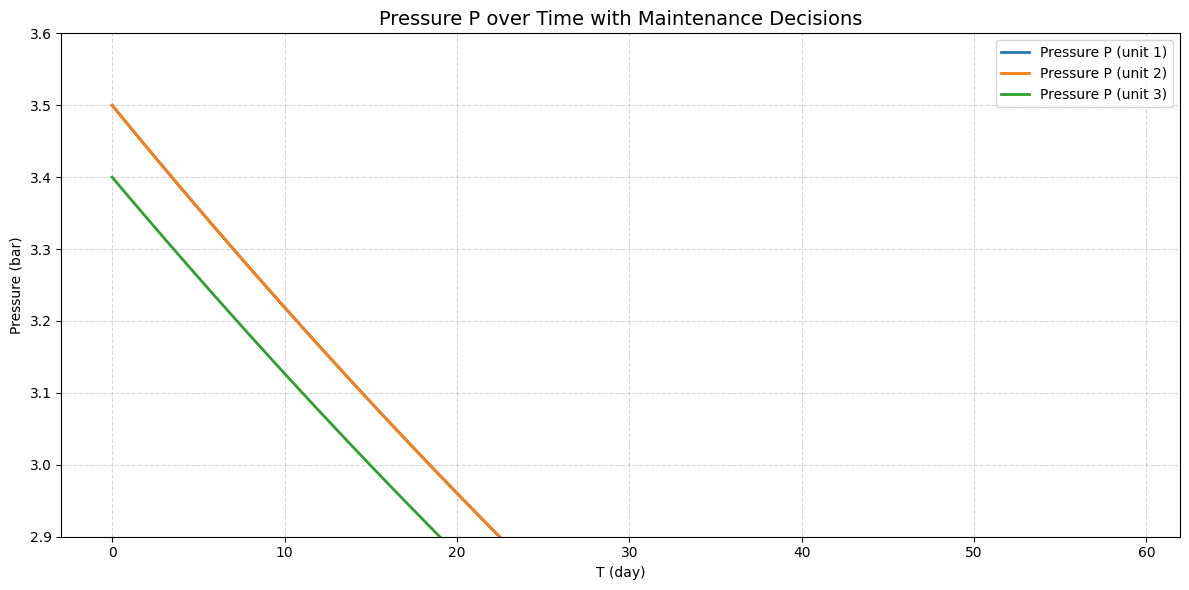

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

if solution:
    # extract solution values
    P_sol = np.zeros((T, N))
    x_sol = np.zeros((T, N))
    y_sol = np.zeros((T, N))

    for t in range(T):
        for i in range(N):
            P_sol[t, i] = P[t, i].solution_value
            x_sol[t, i] = x[t, i].solution_value
            y_sol[t, i] = y[t, i].solution_value

    # plotting
    plt.figure(figsize=(12, 6))
    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for i in range(N):
        plt.plot(range(T), P_sol[:, i], label=f'Pressure P (unit {i+1})', color=colors[i], lw=2)

        # mark COPER times
        coper_times = [t for t in range(T) if x_sol[t, i] > 0.5]
        for t in coper_times:
            plt.axvline(t, color=colors[i], linestyle='--', alpha=0.4)
            plt.text(t, P_max-0.05, f'C{i+1}', rotation=90, fontsize=8, color=colors[i])

        # mark MANT times
        mant_times = [t for t in range(T) if y_sol[t, i] > 0.5]
        for t in mant_times:
            plt.axvline(t, color=colors[i], linestyle=':', alpha=0.6)
            plt.text(t, P_max-0.15, f'M{i+1}', rotation=90, fontsize=8, color=colors[i])

    plt.title("Pressure P over Time with Maintenance Decisions", fontsize=14)
    plt.xlabel("T (day)")
    plt.ylabel("Pressure (bar)")
    plt.ylim(P_threshold-0.1, P_max+0.1)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [ ]:
import plotly.graph_objects as go
import numpy as np

if solution:
    # extract solution values
    P_sol = np.zeros((T, N))
    x_sol = np.zeros((T, N))
    y_sol = np.zeros((T, N))

    for t in range(T):
        for i in range(N):
            P_sol[t, i] = P[t, i].solution_value
            x_sol[t, i] = x[t, i].solution_value
            y_sol[t, i] = y[t, i].solution_value

    # create interactive plot
    fig = go.Figure()

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # colors for three units

    for i in range(N):
        # pressure curve
        fig.add_trace(go.Scatter(
            x=list(range(T)),
            y=P_sol[:, i],
            mode='lines',
            name=f'Pressure - Unit {i+1}',
            line=dict(width=2, color=colors[i])
        ))

        # COPER maintenance points
        coper_times = [t for t in range(T) if x_sol[t, i] > 0.5]
        fig.add_trace(go.Scatter(
            x=coper_times,
            y=[P_sol[t, i] for t in coper_times],
            mode='markers',
            name=f'COPER - Unit {i+1}',
            marker=dict(symbol='triangle-up', color=colors[i], size=10, line=dict(width=1, color='black'))
        ))

        # MANT maintenance points
        mant_times = [t for t in range(T) if y_sol[t, i] > 0.5]
        fig.add_trace(go.Scatter(
            x=mant_times,
            y=[P_sol[t, i] for t in mant_times],
            mode='markers',
            name=f'MANT - Unit {i+1}',
            marker=dict(symbol='star', color=colors[i], size=10, line=dict(width=1, color='black'))
        ))

    # threshold lines
    fig.add_hline(y=P_threshold, line_dash="dot", line_color="red", annotation_text="Threshold")
    fig.add_hline(y=P_max, line_dash="dot", line_color="green", annotation_text="P_max")

    # layout
    fig.update_layout(
        title="Pressure P over Time with Maintenance Decisions",
        xaxis_title="T (day)",
        yaxis_title="Pressure (bar)",
        legend_title="Legend",
        template="plotly_white",
        hovermode="x unified",
        width=1000,
        height=600
    )

    fig.show()
else:
    print("❌ No solution found. Cannot plot results.")


In [18]:
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
N = 3              # nb of CSEM
J = 20             # nb of tasks
T = 360              # total time
C_COPER = 15600        # COPER action cost
C_MANT = 48000         # MANT action cost
C_leak = 100 * 25200         # leakage cost per kg SF6
b_COPER = 4        # COPER operation duration
b_MANT = 50         # MANT operation duration
M1 = 400             # Big-M constant
M2 = 1e7
# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2
# alpha values (example, not the real values)
alpha_init = [0.005,0.006, 0.0045]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]
# initial pressures 
P_init = [3.5, 3.5, 3.4]
# Volume
V = [1, 1, 1]

# coefficient to translate pressure to leakage mass
K = []
for i in range(N):
    K.append(10**2 * 146 * V[i] / (8.314 * 293.15))

# Basic CR leakage cost
B_CR = []
for i in range(N):
    B_CR.append((T*alpha_init[i]/(3.5-3.2)) * K[i] * C_leak)
    

mdl = Model('gas_system_maintenance')

# decision variables
x_COPER = mdl.binary_var_matrix(N,J, name='x_COPER')
x_MANT = mdl.binary_var_matrix(N, J, name='x_MANT')
y_COPER = mdl.continuous_var_matrix(N, J,lb=0, name='y_COPER')  # product x R_COPER
y_MANT = mdl.continuous_var_matrix(N, J,lb=0, name='y_MANT')      # product x R_MANT
t = mdl.integer_var_matrix(N, J, name='t')
z = mdl.binary_var_cube(N, J, J, name='z')
t_END = mdl.integer_var_matrix(N, J, name='t_END')
alpha_eff = mdl.continuous_var_matrix(N, J, name='alpha_eff')  # effective alpha after task k for CSEM i
R_COPER = mdl.continuous_var_matrix(N, J, name='R_COPER')   # cost reduction due to COPER
R_MANT = mdl.continuous_var_matrix(N, J, name='R_MANT')   # cost reduction due to MANT


# # non overlapping constraints
# for i in range(N):
#     for k in range(J):
#         for l in range(J):
#             if k != l:
#                 mdl.add(t[i,k] + b_COPER* x_COPER[i,k] + b_MANT*x_MANT[i,k] <= t[i,l] + M1*(1-z[i,k,l]))
#                 mdl.add(t[i,l] + b_MANT*x_MANT[i,l] + b_COPER*x_COPER[i,l] <= t[i,k] + M1*z[i,k,l])

# each CSEM can have at most one task COPER or MANT
for i in range(N):
    mdl.add(mdl.sum(x_COPER[i,k] + x_MANT[i,k] for k in range(J)) <= 1)

# Event end times
for i in range(N):
    for k in range(J):
        mdl.add(t_END[i,k] == t[i,k] + b_COPER*x_COPER[i,k] + b_MANT*x_MANT[i,k])
    
# Effective leakage rate
for i in range(N):
    for k in range(J):
        mdl.add(alpha_eff[i,k] == alpha_COPER[i] * x_COPER[i,k] + alpha_MANT[i] * x_MANT[i,k] + alpha_init[i] * (1 - x_COPER[i,k] - x_MANT[i,k]))

# # contains only complete events
# for i in range(N):
#     for k in range(J):
#         mdl.add(t_END[i,k] <= T + M * (1 - x_COPER[i,k] - x_MANT[i,k]))

# Cost reduction due to COPER/MANT
for i in range(N):
    for k in range(J):
        mdl.add(R_COPER[i,k] == C_leak * K[i] * (alpha_init[i] - alpha_COPER[i])* (T- t_END[i,k]))
        mdl.add(R_MANT[i,k] == C_leak * K[i] * (alpha_init[i] - alpha_MANT[i])* (T- t_END[i,k]))

# y definition
for i in range(N):
    for k in range(J):
        mdl.add(y_COPER[i,k] <= M2 * x_COPER[i,k])
        mdl.add(y_COPER[i,k] <= R_COPER[i,k])
        mdl.add(y_COPER[i,k] >= R_COPER[i,k] - M2 * (1 - x_COPER[i,k]))
        mdl.add(y_MANT[i,k] >= 0)

        mdl.add(y_MANT[i,k] <= M2 * x_MANT[i,k])
        mdl.add(y_MANT[i,k] <= R_MANT[i,k])
        mdl.add(y_MANT[i,k] >= R_MANT[i,k] - M2 * (1 - x_MANT[i,k])) 
        mdl.add(y_MANT[i,k] >= 0)
    
        
# objective function
action_cost = mdl.sum(C_COPER*x_COPER[i,k] + C_MANT*x_MANT[i,k] for i in range(N) for k in range(J))
BasicCR_cost = mdl.sum(B_CR[i] for i in range(N))
leakage_cost_reduction = mdl.sum(y_COPER[i,k] + y_MANT[i,k] for i in range(N) for k in range(J))

mdl.minimize(action_cost + BasicCR_cost - leakage_cost_reduction)

# solve the model
sol = mdl.solve()
if sol:
    print('Objective value:', sol.objective_value)
    
    # print COPER and MANT scheduling
    for i in range(N):
        print(f"\nCSEM {i}:")
        print("COPER events:")
        for k in range(J):
            if x_COPER[i, k].solution_value > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].solution_value:.2f} units")
        print("MANT events:")
        for k in range(J):
            if x_MANT[i, k].solution_value > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].solution_value:.2f} units")
else:
    print("No solution found.")



Objective value: 251049038.79968622

CSEM 0:
COPER events:
MANT events:
  Event 1, Time: 137.00 units

CSEM 1:
COPER events:
MANT events:
  Event 20, Time: 166.00 units

CSEM 2:
COPER events:
MANT events:
  Event 20, Time: 117.00 units
